In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
DRIVE_PROJECT = Path('/content/drive/MyDrive/SOFTS-HNweather')
DATA_PATH = DRIVE_PROJECT / 'hanoi_weather.csv'
DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)

print('Đường dẫn dataset:', DATA_PATH)
if not DATA_PATH.exists():
    raise FileNotFoundError(
        'Chưa tìm thấy dataset. Hãy tải hanoi_weather.csv lên Google Drive tại '
        'MyDrive/SOFTS-HNweather/hanoi_weather.csv rồi chạy lại ô này.'
    )
print('Dung lượng CSV (MB):', round(DATA_PATH.stat().st_size / 1024**2, 2))


Mounted at /content/drive
Đường dẫn dataset: /content/drive/MyDrive/SOFTS-HNweather/hanoi_weather.csv
Dung lượng CSV (MB): 29.13


In [2]:
import os
import sys
import subprocess
from pathlib import Path

repo = Path("/content/SOFTS-HNweather")

# Neu thu muc bi mat sau khi khoi dong lai Colab, tai lai ma nguon
if not repo.exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/Secilia-Cxy/SOFTS.git",
         str(repo)],
        check=True
    )

# Chuyen vao thu muc SOFTS
os.chdir(repo)
sys.path.insert(0, str(repo))

print("Thu muc:", os.getcwd())
print("exp_custom.py ton tai:", (repo / "exp" / "exp_custom.py").exists())

from exp.exp_custom import Exp_Custom
from models.SOFTS import Model

print("SOFTS import OK")

Thu muc: /content/SOFTS-HNweather
exp_custom.py ton tai: True
SOFTS import OK


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from pathlib import Path
import pandas as pd

csv_path = Path(
    "/content/drive/MyDrive/SOFTS-HNweather/hanoi_weather.csv"
)

if not csv_path.exists():
    print("KHÔNG TÌM THẤY DATASET:", csv_path)
else:
    df = pd.read_csv(csv_path)

    print("Dataset:", csv_path)
    print("Số dòng:", len(df))
    print("Các cột:", df.columns.tolist())
    print("Dữ liệu thiếu:\n", df.isna().sum())
    print("\n5 dòng đầu:")
    print(df.head().to_string(index=False))

Dataset: /content/drive/MyDrive/SOFTS-HNweather/hanoi_weather.csv
Số dòng: 753883
Các cột: ['date', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'cloud_cover']
Dữ liệu thiếu:
 date                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
cloud_cover             0
dtype: int64

5 dòng đầu:
               date  temperature_2m  relative_humidity_2m  precipitation  wind_speed_10m  cloud_cover
1940-01-01 05:00:00            19.6                    44            0.0             6.1            2
1940-01-01 06:00:00            20.2                    43            0.0             7.2            6
1940-01-01 07:00:00            20.4                    42            0.0             6.8            8
1940-01-01 08:00:00            20.5                    42            0.0             6.2            7
1940-01-01 09:00:00            20.1                    43            0.0             5.1            

In [5]:
import re
import os
import sys
import importlib
from pathlib import Path

repo = Path("/content/SOFTS-HNweather")
os.chdir(repo)
sys.path.insert(0, str(repo))

file_path = repo / "exp" / "exp_custom.py"
source = file_path.read_text(encoding="utf-8")

# Huấn luyện: lấy một cửa sổ mỗi 6 giờ
source, train_count = re.subn(
    r"(mode='train',\s*\n\s*stride=)1(\))",
    r"\g<1>getattr(self.args, 'train_stride', 1)\2",
    source,
    count=1,
)

# Validation/test: lấy một cửa sổ mỗi 24 giờ
source, eval_count = re.subn(
    r"(mode='test',\s*\n\s*stride=)1(\))",
    r"\g<1>getattr(self.args, 'eval_stride', 1)\2",
    source,
    count=1,
)

if train_count != 1 or eval_count != 1:
    raise RuntimeError(
        f"Chưa sửa được mã nguồn: train={train_count}, "
        f"evaluation={eval_count}. Dừng để kiểm tra."
    )

file_path.write_text(source, encoding="utf-8")

import exp.exp_custom as exp_custom_module
importlib.reload(exp_custom_module)

Exp_Custom = exp_custom_module.Exp_Custom

print("Đã điều chỉnh thành công.")
print("Train stride: 6 giờ")
print("Validation/test stride: 24 giờ")
print("SOFTS import:", Exp_Custom)

Đã điều chỉnh thành công.
Train stride: 6 giờ
Validation/test stride: 24 giờ
SOFTS import: <class 'exp.exp_custom.Exp_Custom'>


In [9]:
from pathlib import Path
import importlib
import os
import sys

repo = Path("/content/SOFTS-HNweather")
os.chdir(repo)

# Tìm và sửa np.Inf thành np.inf trong các file Python
fixed_files = []

for file_path in repo.rglob("*.py"):
    source = file_path.read_text(encoding="utf-8")

    if "np.Inf" in source:
        source = source.replace("np.Inf", "np.inf")
        file_path.write_text(source, encoding="utf-8")
        fixed_files.append(str(file_path.relative_to(repo)))

print("Các file đã sửa:")
for file_name in fixed_files:
    print("-", file_name)

# Nạp lại module để mã nguồn mới được áp dụng
import utils.tools as tools_module
importlib.reload(tools_module)

import exp.exp_custom as exp_custom_module
importlib.reload(exp_custom_module)

Exp_Custom = exp_custom_module.Exp_Custom

print("Đã sửa lỗi tương thích NumPy.")

Các file đã sửa:
- utils/tools.py
Đã sửa lỗi tương thích NumPy.


In [11]:
import os
import importlib
from pathlib import Path

repo = Path("/content/SOFTS-HNweather")
os.chdir(repo)

file_path = repo / "exp" / "exp_custom.py"
source = file_path.read_text(encoding="utf-8")

old = '''            print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f} Test Loss: {4:.7f}".format(
                epoch + 1, train_steps, train_loss, vali_loss, test_loss))'''

new = '''            if test_loss is None:
                print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f}".format(
                    epoch + 1, train_steps, train_loss, vali_loss))
            else:
                print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f} Test Loss: {4:.7f}".format(
                    epoch + 1, train_steps, train_loss, vali_loss, test_loss))'''

if old not in source:
    raise RuntimeError(
        "Không tìm thấy đoạn code cần sửa. "
        "Chưa thay đổi file; hãy gửi nội dung quanh dòng 200."
    )

source = source.replace(old, new, 1)
file_path.write_text(source, encoding="utf-8")

import exp.exp_custom as exp_custom_module
importlib.reload(exp_custom_module)

Exp_Custom = exp_custom_module.Exp_Custom

print("Đã sửa lỗi in test_loss.")

Đã sửa lỗi in test_loss.


In [12]:
import json
import random
import shutil
import time
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch
import joblib
from sklearn.preprocessing import StandardScaler

# Đường dẫn
repo = Path("/content/SOFTS-HNweather")
drive_dir = Path("/content/drive/MyDrive/SOFTS-HNweather")
csv_path = drive_dir / "hanoi_weather.csv"

assert csv_path.exists(), f"Không tìm thấy: {csv_path}"
assert torch.cuda.is_available(), "Colab chưa nhận GPU!"

os.chdir(repo)

# Cấu hình dự báo
SEQ_LEN = 168
PRED_LEN = 24
SETTING = "HanoiWeather_SOFTS_168_24"

features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover",
]

# Đọc và kiểm tra dữ liệu
df = pd.read_csv(csv_path)
df["date"] = pd.to_datetime(df["date"])

assert df["date"].is_monotonic_increasing
assert not df.isna().any().any()
assert not df["date"].duplicated().any()

# Chia 70% / 10% / 20% theo thời gian
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_raw = df.iloc[:train_end].copy()
vali_raw = df.iloc[train_end - SEQ_LEN:val_end].copy()
test_raw = df.iloc[val_end - SEQ_LEN:].copy()

# Chỉ học tham số chuẩn hóa từ tập train
scaler = StandardScaler()
scaler.fit(train_raw[features])

def scale_data(frame):
    result = frame.copy()

    # Chuyển các cột đặc trưng sang số thực trước
    result[features] = result[features].astype("float64")

    # Chuẩn hóa dữ liệu bằng StandardScaler
    result[features] = scaler.transform(result[features])

    return result

train_data = scale_data(train_raw)
vali_data = scale_data(vali_raw)
test_data = scale_data(test_raw)

print("Tổng số dòng:", n)
print("Train:", len(train_raw))
print("Validation:", len(vali_raw))
print("Test:", len(test_raw))
print("GPU:", torch.cuda.get_device_name(0))

# Cấu hình SOFTS
random.seed(2026)
np.random.seed(2026)
torch.manual_seed(2026)
torch.cuda.manual_seed_all(2026)

args = SimpleNamespace(
    model="SOFTS",
    seq_len=SEQ_LEN,
    pred_len=PRED_LEN,
    features="M",
    freq="h",

    d_model=128,
    d_core=64,
    d_ff=128,
    e_layers=2,
    dropout=0.0,
    activation="gelu",
    use_norm=True,

    learning_rate=0.0003,
    lradj="cosine",
    train_epochs=10,
    patience=3,
    batch_size=64,
    num_workers=0,

    use_gpu=True,
    gpu="0",
    save_model=True,
    checkpoints="./checkpoints/",

    train_stride=6,
    eval_stride=24,
)

# Huấn luyện
exp = Exp_Custom(args)

start = time.time()

exp.train(
    SETTING,
    train_data,
    vali_data=vali_data,
    test_data=None,
)

print(f"Thời gian huấn luyện: {(time.time()-start)/60:.2f} phút")

# Đánh giá sau khi chọn checkpoint tốt nhất
print("\n=== ĐÁNH GIÁ TRÊN TEST ===")
exp.test(SETTING, test_data)

# Lưu kết quả để dùng ngoài Colab
local_model_dir = repo / "checkpoints" / SETTING
drive_model_dir = drive_dir / "checkpoints" / SETTING
drive_model_dir.mkdir(parents=True, exist_ok=True)

checkpoint = local_model_dir / "checkpoint.pth"
assert checkpoint.exists(), f"Không tìm thấy checkpoint: {checkpoint}"

shutil.copy2(checkpoint, drive_model_dir / "checkpoint.pth")
joblib.dump(scaler, drive_model_dir / "scaler.pkl")

config = {
    "model": "SOFTS",
    "seq_len": SEQ_LEN,
    "pred_len": PRED_LEN,
    "features": features,
    "freq": "h",
    "d_model": 128,
    "d_core": 64,
    "d_ff": 128,
    "e_layers": 2,
    "use_norm": True,
}

with open(drive_model_dir / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("\nĐÃ LƯU MÔ HÌNH VÀO GOOGLE DRIVE:")
print(drive_model_dir)
print("checkpoint.pth, scaler.pkl, config.json")

Tổng số dòng: 753883
Train: 527718
Validation: 75556
Test: 150945
GPU: Tesla T4
Use GPU: cuda:0
	iters: 100, epoch: 1 | loss: 0.4325372
	speed: 0.0076s/iter; left time: 104.2260s
	iters: 200, epoch: 1 | loss: 0.5018690
	speed: 0.0074s/iter; left time: 100.2196s
	iters: 300, epoch: 1 | loss: 0.8835489
	speed: 0.0073s/iter; left time: 97.6947s
	iters: 400, epoch: 1 | loss: 0.6150416
	speed: 0.0076s/iter; left time: 101.5844s
	iters: 500, epoch: 1 | loss: 0.4079186
	speed: 0.0073s/iter; left time: 96.8424s
	iters: 600, epoch: 1 | loss: 0.4975496
	speed: 0.0077s/iter; left time: 101.5941s
	iters: 700, epoch: 1 | loss: 0.5131415
	speed: 0.0072s/iter; left time: 93.2709s
	iters: 800, epoch: 1 | loss: 0.4116071
	speed: 0.0073s/iter; left time: 94.4675s
	iters: 900, epoch: 1 | loss: 0.4076112
	speed: 0.0074s/iter; left time: 94.5251s
	iters: 1000, epoch: 1 | loss: 0.5239230
	speed: 0.0071s/iter; left time: 90.2238s
	iters: 1100, epoch: 1 | loss: 0.5203424
	speed: 0.0074s/iter; left time: 93.43

Thiết bị: cuda:0
Số giờ đầu vào: 168
Số giờ dự báo: 24
Bước dịch giữa các cửa sổ: 24

Hoàn thành dự báo.
Kích thước dự báo: (6281, 24, 5)
Kích thước thực tế: (6281, 24, 5)

===== SAI SỐ TRÊN TẬP TEST, ĐƠN VỊ GỐC =====


,Biến thời tiết,Đơn vị,MAE,RMSE
0,temperature_2m,°C,1.3154,1.812400
1,relative_humidity_2m,%,5.5028,7.406800
2,precipitation,mm,0.2441,0.763300
3,wind_speed_10m,km/h,2.3621,3.168800
4,cloud_cover,%,18.2652,25.614201


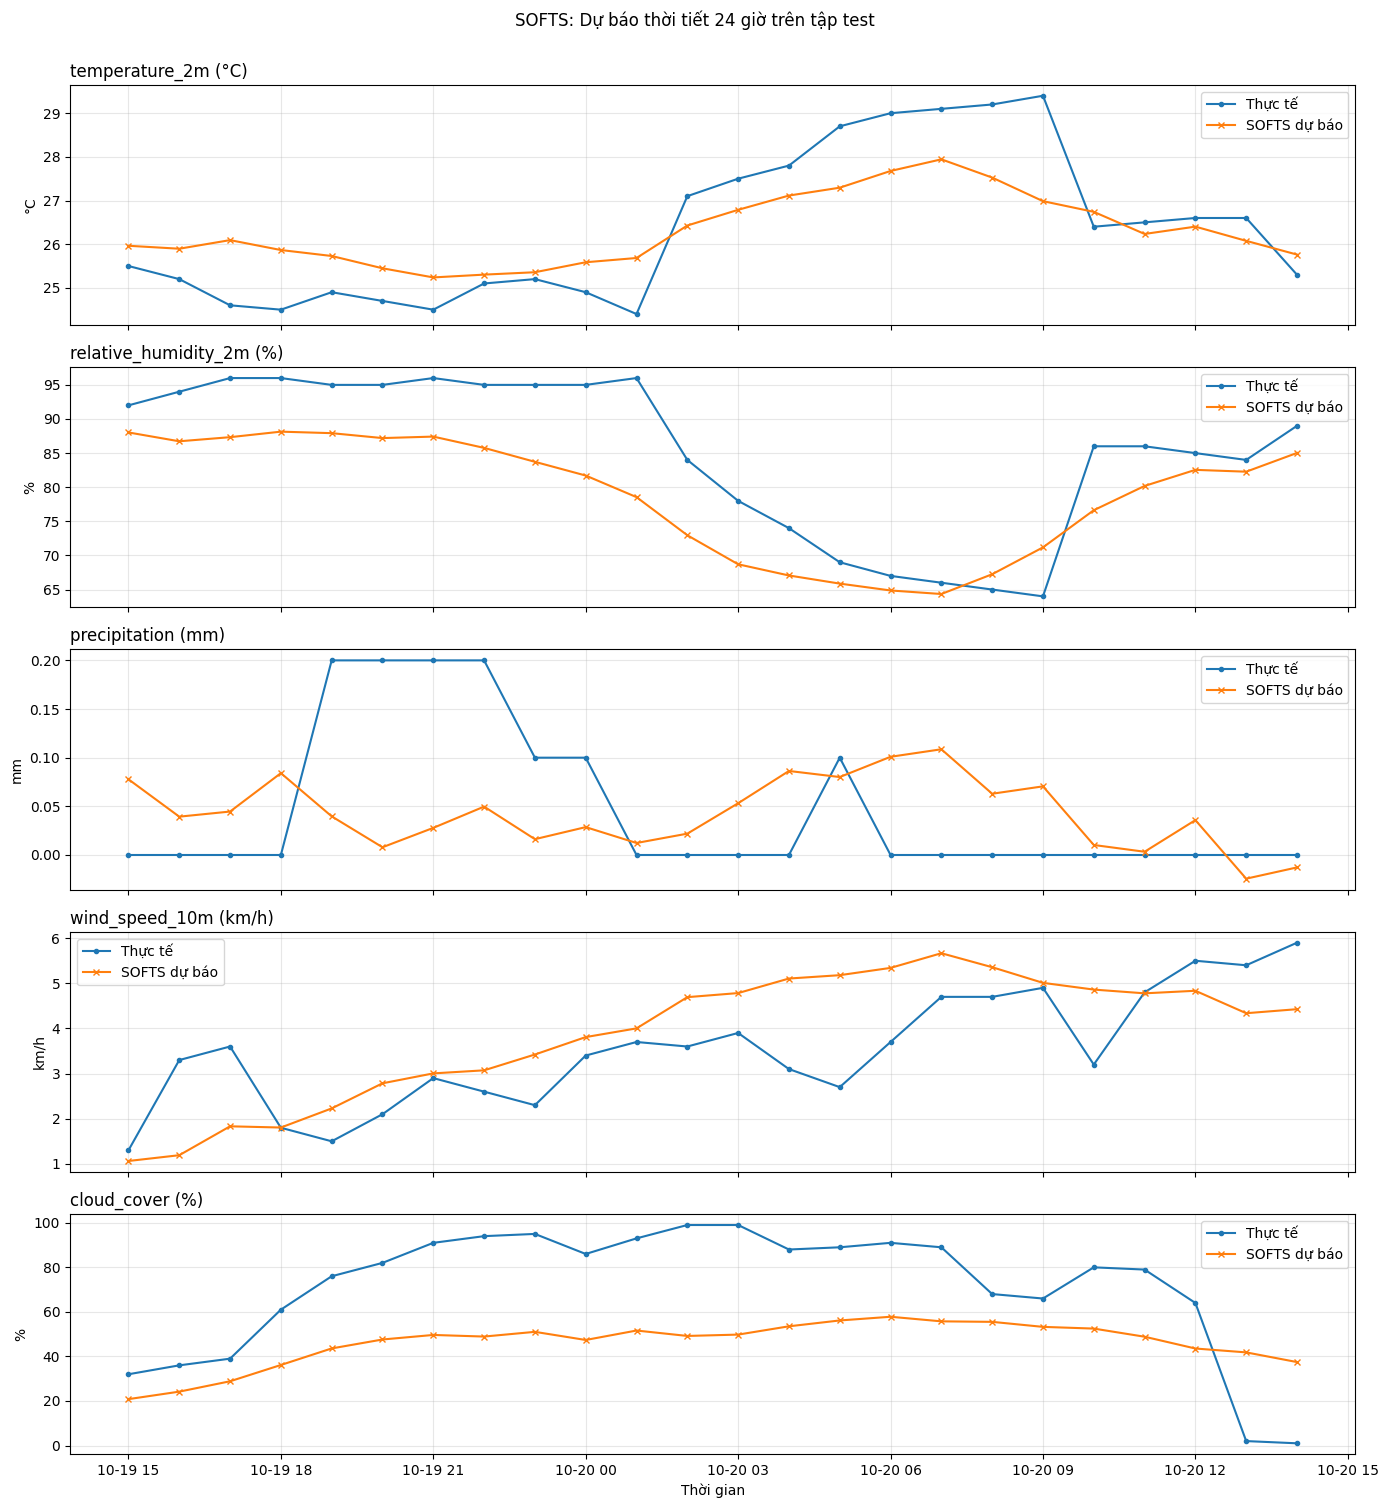


===== ĐÃ LƯU KẾT QUẢ =====
File dự báo: /content/drive/MyDrive/SOFTS-HNweather/evaluation/test_predictions_24h.csv
File sai số: /content/drive/MyDrive/SOFTS-HNweather/evaluation/test_metrics_by_feature.csv
Số cửa sổ dự báo: 6281
Số dòng dự báo: 150744
Khoảng thời gian: 2008-10-19 15:00:00 đến 2025-12-30 14:00:00


In [14]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ==================================================
# 1. KIỂM TRA MÔ HÌNH VÀ DỮ LIỆU
# ==================================================
repo = Path("/content/SOFTS-HNweather")
os.chdir(repo)

assert "exp" in globals(), "Không tìm thấy biến exp. Hãy chạy lại cell huấn luyện."
assert "test_data" in globals(), "Không tìm thấy test_data."
assert "scaler" in globals(), "Không tìm thấy scaler."
assert "features" in globals(), "Không tìm thấy danh sách features."

SEQ_LEN = args.seq_len
PRED_LEN = args.pred_len
EVAL_STRIDE = args.eval_stride

device = next(exp.model.parameters()).device

# Nạp lại trọng số tốt nhất đã lưu
checkpoint_path = repo / "checkpoints" / SETTING / "checkpoint.pth"
assert checkpoint_path.exists(), f"Không tìm thấy checkpoint: {checkpoint_path}"

state_dict = torch.load(checkpoint_path, map_location=device)
exp.model.load_state_dict(state_dict)
exp.model.eval()

print("Thiết bị:", device)
print("Số giờ đầu vào:", SEQ_LEN)
print("Số giờ dự báo:", PRED_LEN)
print("Bước dịch giữa các cửa sổ:", EVAL_STRIDE)

# ==================================================
# 2. TẠO TEST LOADER
# ==================================================
test_dataset, test_loader = exp._get_data(
    test_data,
    mode="test",
    stride=EVAL_STRIDE
)

pred_batches = []
true_batches = []

# ==================================================
# 3. CHẠY DỰ BÁO
# ==================================================
with torch.no_grad():
    for batch_x, batch_y, batch_x_mark in test_loader:

        batch_x = batch_x.float().to(device)
        batch_y = batch_y.float().to(device)
        batch_x_mark = batch_x_mark.float().to(device)

        outputs = exp.model(
            batch_x,
            batch_x_mark,
            None,
            None
        )

        if isinstance(outputs, (tuple, list)):
            outputs = outputs[0]

        outputs = outputs[:, -PRED_LEN:, :]
        targets = batch_y[:, -PRED_LEN:, :]

        if outputs.shape != targets.shape:
            raise ValueError(
                f"Kích thước dự báo {outputs.shape} "
                f"khác kích thước thực tế {targets.shape}"
            )

        pred_batches.append(outputs.cpu().numpy())
        true_batches.append(targets.cpu().numpy())

pred_scaled = np.concatenate(pred_batches, axis=0)
true_scaled = np.concatenate(true_batches, axis=0)

print("\nHoàn thành dự báo.")
print("Kích thước dự báo:", pred_scaled.shape)
print("Kích thước thực tế:", true_scaled.shape)

# ==================================================
# 4. CHUYỂN VỀ ĐƠN VỊ THỜI TIẾT GỐC
# ==================================================
n_features = len(features)

pred_original = scaler.inverse_transform(
    pred_scaled.reshape(-1, n_features)
).reshape(pred_scaled.shape)

true_original = scaler.inverse_transform(
    true_scaled.reshape(-1, n_features)
).reshape(true_scaled.shape)

# ==================================================
# 5. TÍNH MAE VÀ RMSE RIÊNG CHO TỪNG BIẾN
# ==================================================
units = {
    "temperature_2m": "°C",
    "relative_humidity_2m": "%",
    "precipitation": "mm",
    "wind_speed_10m": "km/h",
    "cloud_cover": "%"
}

metric_rows = []

for i, feature in enumerate(features):
    actual = true_original[:, :, i].ravel()
    predicted = pred_original[:, :, i].ravel()

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    metric_rows.append({
        "Biến thời tiết": feature,
        "Đơn vị": units.get(feature, ""),
        "MAE": mae,
        "RMSE": rmse
    })

metrics_df = pd.DataFrame(metric_rows)

print("\n===== SAI SỐ TRÊN TẬP TEST, ĐƠN VỊ GỐC =====")
display(metrics_df.round(4))

# ==================================================
# 6. VẼ BIỂU ĐỒ CHO MỘT LẦN DỰ BÁO 24 GIỜ
# ==================================================
first_dates = pd.to_datetime(
    test_data["date"].iloc[SEQ_LEN:SEQ_LEN + PRED_LEN]
).reset_index(drop=True)

if len(first_dates) != PRED_LEN:
    raise ValueError("Không đủ mốc thời gian để vẽ biểu đồ.")

fig, axes = plt.subplots(
    n_features, 1,
    figsize=(14, 3 * n_features),
    sharex=True
)

for i, feature in enumerate(features):
    ax = axes[i]

    ax.plot(
        first_dates,
        true_original[0, :, i],
        marker="o",
        markersize=3,
        label="Thực tế"
    )
    ax.plot(
        first_dates,
        pred_original[0, :, i],
        marker="x",
        markersize=4,
        label="SOFTS dự báo"
    )

    ax.set_title(f"{feature} ({units.get(feature, '')})", loc="left")
    ax.set_ylabel(units.get(feature, ""))
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Thời gian")
plt.suptitle("SOFTS: Dự báo thời tiết 24 giờ trên tập test", y=1.002)
plt.tight_layout()
plt.show()

# ==================================================
# 7. LƯU KẾT QUẢ VÀO GOOGLE DRIVE
# ==================================================
# Các cửa sổ dự báo được lưu theo thứ tự thời gian.
# Mỗi dòng tương ứng một mốc giờ dự báo.

assert EVAL_STRIDE == PRED_LEN, (
    "Cell lưu CSV này đang giả định bước dịch cửa sổ "
    "bằng đúng độ dài dự báo."
)

n_windows = pred_original.shape[0]
n_rows = n_windows * PRED_LEN

forecast_dates = pd.to_datetime(
    test_data["date"].iloc[
        SEQ_LEN:SEQ_LEN + n_rows
    ]
).reset_index(drop=True)

if len(forecast_dates) != n_rows:
    raise ValueError("Số mốc thời gian không khớp với số dự báo.")

predictions_df = pd.DataFrame({"date": forecast_dates})

for i, feature in enumerate(features):
    predictions_df[f"actual_{feature}"] = true_original[:, :, i].reshape(-1)
    predictions_df[f"predicted_{feature}"] = pred_original[:, :, i].reshape(-1)

drive_dir = Path("/content/drive/MyDrive/SOFTS-HNweather/evaluation")
drive_dir.mkdir(parents=True, exist_ok=True)

prediction_file = drive_dir / "test_predictions_24h.csv"
metrics_file = drive_dir / "test_metrics_by_feature.csv"

predictions_df.to_csv(prediction_file, index=False)
metrics_df.to_csv(metrics_file, index=False)

print("\n===== ĐÃ LƯU KẾT QUẢ =====")
print("File dự báo:", prediction_file)
print("File sai số:", metrics_file)
print("Số cửa sổ dự báo:", n_windows)
print("Số dòng dự báo:", len(predictions_df))
print("Khoảng thời gian:", forecast_dates.iloc[0], "đến", forecast_dates.iloc[-1])

===== SO SÁNH SOFTS VỚI BASELINE =====


,Biến thời tiết,SOFTS MAE,Baseline MAE,SOFTS RMSE,Baseline RMSE,MAE cải thiện (%)
0,temperature_2m,1.3154,1.4653,1.8124,2.0496,10.2315
1,relative_humidity_2m,5.5028,6.0933,7.4068,8.6210,9.6916
2,precipitation,0.2441,0.3164,0.7633,1.0839,22.8478
3,wind_speed_10m,2.3621,3.0854,3.1688,4.1674,23.4418
4,cloud_cover,18.2652,21.0261,25.6142,33.6589,13.1310


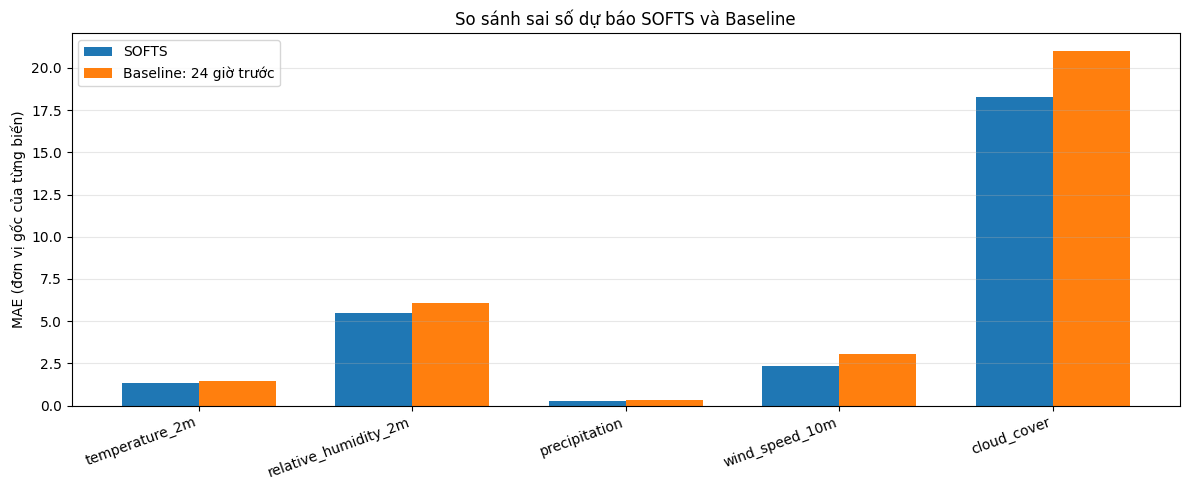

Đã lưu bảng so sánh: /content/drive/MyDrive/SOFTS-HNweather/evaluation/softs_vs_baseline.csv


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. TẠO DỰ BÁO ĐƯỜNG CƠ SỞ
# ==========================================
baseline_batches = []
actual_batches = []

for batch_x, batch_y, batch_x_mark in test_loader:
    # Lấy 24 giờ cuối của đầu vào làm dự báo cho 24 giờ tiếp theo
    baseline_batches.append(
        batch_x[:, -PRED_LEN:, :].cpu().numpy()
    )

    # Giá trị thực tế trong 24 giờ cần dự báo
    actual_batches.append(
        batch_y[:, -PRED_LEN:, :].cpu().numpy()
    )

baseline_scaled = np.concatenate(baseline_batches, axis=0)
actual_scaled = np.concatenate(actual_batches, axis=0)

assert baseline_scaled.shape == pred_scaled.shape
assert actual_scaled.shape == true_scaled.shape

# Chuyển về đơn vị gốc
n_features = len(features)

baseline_original = scaler.inverse_transform(
    baseline_scaled.reshape(-1, n_features)
).reshape(baseline_scaled.shape)

actual_original = scaler.inverse_transform(
    actual_scaled.reshape(-1, n_features)
).reshape(actual_scaled.shape)

# ==========================================
# 2. TÍNH MAE VÀ RMSE CHO HAI PHƯƠNG PHÁP
# ==========================================
comparison_rows = []

for i, feature in enumerate(features):
    actual = actual_original[:, :, i].ravel()
    softs_pred = pred_original[:, :, i].ravel()
    baseline_pred = baseline_original[:, :, i].ravel()

    softs_mae = np.mean(np.abs(actual - softs_pred))
    softs_rmse = np.sqrt(np.mean((actual - softs_pred) ** 2))

    baseline_mae = np.mean(np.abs(actual - baseline_pred))
    baseline_rmse = np.sqrt(np.mean((actual - baseline_pred) ** 2))

    # Phần trăm giảm MAE: số dương nghĩa là SOFTS tốt hơn
    improvement = (
        (baseline_mae - softs_mae) / baseline_mae * 100
        if baseline_mae > 0 else np.nan
    )

    comparison_rows.append({
        "Biến thời tiết": feature,
        "SOFTS MAE": softs_mae,
        "Baseline MAE": baseline_mae,
        "SOFTS RMSE": softs_rmse,
        "Baseline RMSE": baseline_rmse,
        "MAE cải thiện (%)": improvement
    })

comparison_df = pd.DataFrame(comparison_rows)

print("===== SO SÁNH SOFTS VỚI BASELINE =====")
display(comparison_df.round(4))

# ==========================================
# 3. VẼ BIỂU ĐỒ SO SÁNH MAE
# ==========================================
x = np.arange(len(features))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    x - width / 2,
    comparison_df["SOFTS MAE"],
    width,
    label="SOFTS"
)

ax.bar(
    x + width / 2,
    comparison_df["Baseline MAE"],
    width,
    label="Baseline: 24 giờ trước"
)

ax.set_xticks(x)
ax.set_xticklabels(features, rotation=20, ha="right")
ax.set_ylabel("MAE (đơn vị gốc của từng biến)")
ax.set_title("So sánh sai số dự báo SOFTS và Baseline")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 4. LƯU BẢNG SO SÁNH
# ==========================================
comparison_file = (
    "/content/drive/MyDrive/SOFTS-HNweather/"
    "evaluation/softs_vs_baseline.csv"
)

comparison_df.to_csv(comparison_file, index=False)
print("Đã lưu bảng so sánh:", comparison_file)

===== SAI SỐ THEO KHOẢNG CÁCH DỰ BÁO =====


Biến thời tiết,cloud_cover,precipitation,relative_humidity_2m,temperature_2m,wind_speed_10m
Giờ dự báo,,,,,
1,7.012000,0.143,1.753,0.330,0.847
2,10.677000,0.200,2.190,0.396,1.281
3,13.347000,0.234,3.415,0.876,1.559
4,15.068000,0.255,3.151,0.757,1.747
5,16.222000,0.268,3.282,0.710,1.890
6,17.073999,0.277,4.190,0.949,1.968
7,17.266001,0.266,4.458,0.950,2.025
8,16.930000,0.265,4.689,0.924,2.070
9,17.087000,0.257,5.341,1.028,2.098


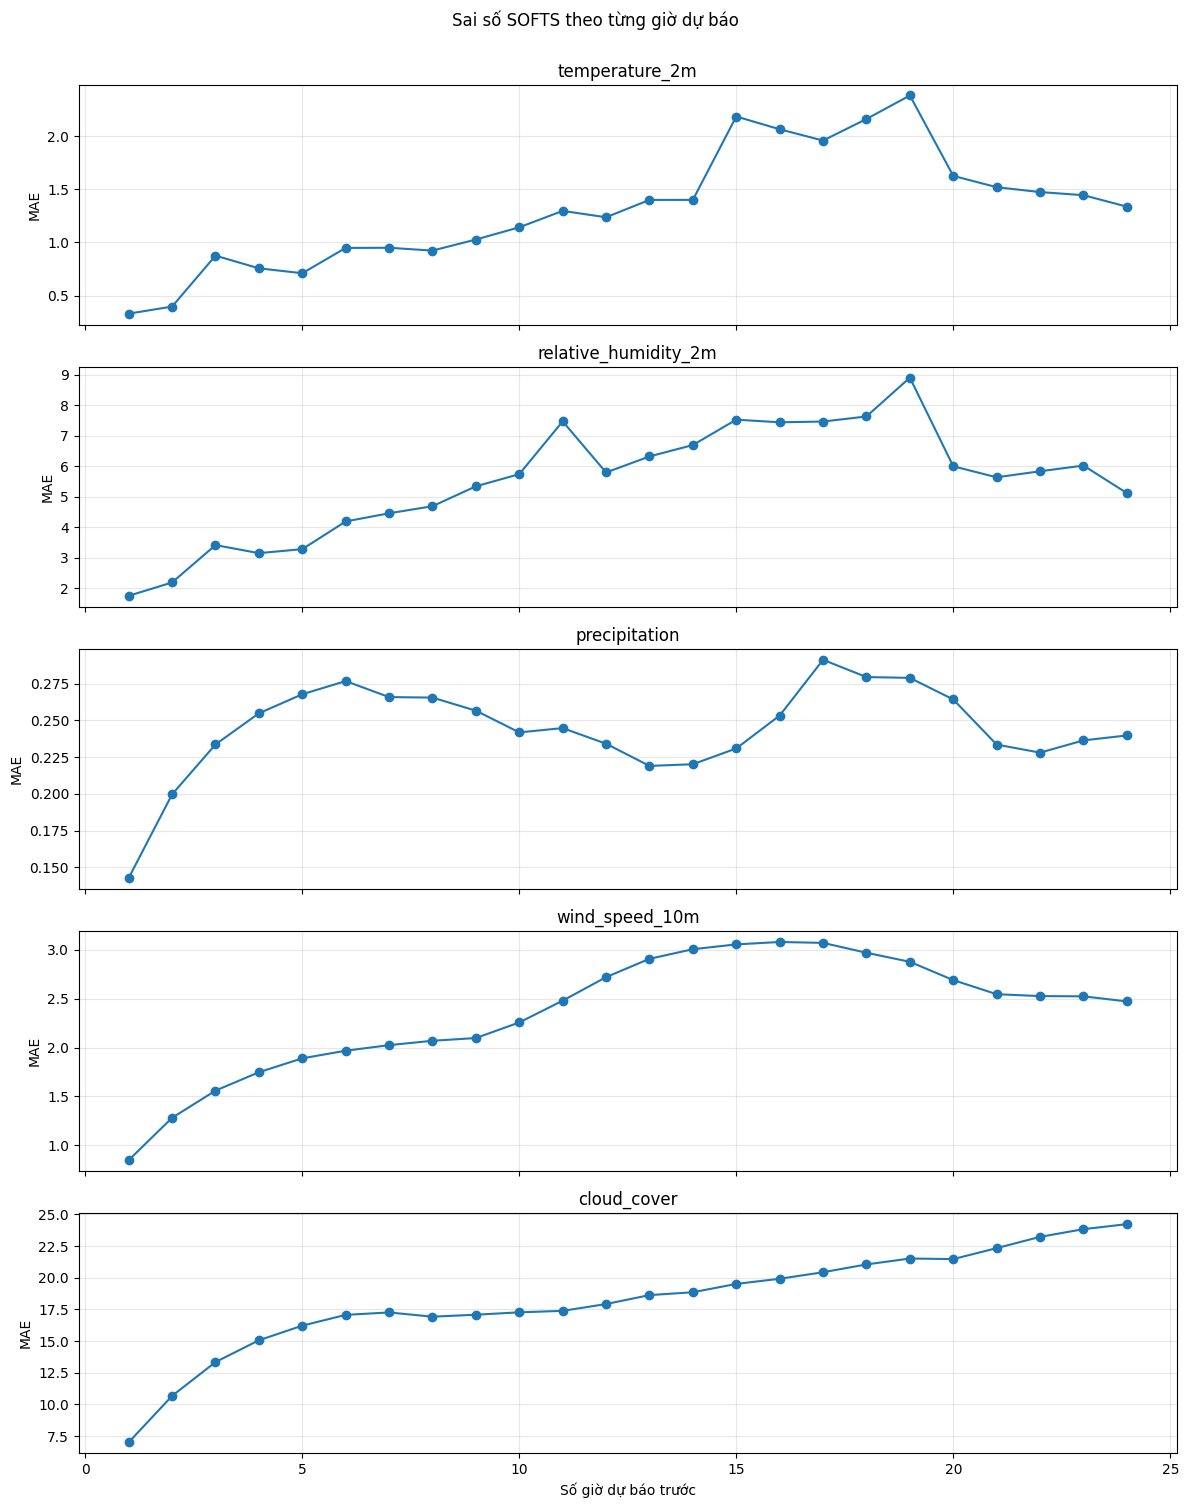

===== KIỂM TRA GIÁ TRỊ DỰ BÁO =====


,Biến,Giá trị nhỏ nhất,Giá trị lớn nhất,Số giá trị vi phạm,Tỷ lệ vi phạm (%),Quy tắc
0,temperature_2m,6.822700,39.159801,0,0.0000,Chưa kiểm tra giới hạn vật lý
1,relative_humidity_2m,28.261101,103.162903,61,0.0405,Phải nằm trong 0–100%
2,precipitation,-1.125300,19.209600,24913,16.5267,Không được âm
3,wind_speed_10m,0.055600,35.847000,0,0.0000,Không được âm
4,cloud_cover,-12.681000,133.107697,8390,5.5657,Phải nằm trong 0–100%


Đã lưu bảng đánh giá vào: /content/drive/MyDrive/SOFTS-HNweather/evaluation


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. MAE THEO TỪNG GIỜ DỰ BÁO
# ==========================================
horizon_rows = []

for h in range(PRED_LEN):
    for i, feature in enumerate(features):
        actual = true_original[:, h, i]
        predicted = pred_original[:, h, i]

        mae = np.mean(np.abs(actual - predicted))
        rmse = np.sqrt(np.mean((actual - predicted) ** 2))

        horizon_rows.append({
            "Giờ dự báo": h + 1,
            "Biến thời tiết": feature,
            "MAE": mae,
            "RMSE": rmse
        })

horizon_df = pd.DataFrame(horizon_rows)

print("===== SAI SỐ THEO KHOẢNG CÁCH DỰ BÁO =====")
display(
    horizon_df.pivot(
        index="Giờ dự báo",
        columns="Biến thời tiết",
        values="MAE"
    ).round(3)
)

# ==========================================
# 2. VẼ MAE TỪ GIỜ 1 ĐẾN GIỜ 24
# ==========================================
fig, axes = plt.subplots(
    len(features), 1,
    figsize=(12, 3 * len(features)),
    sharex=True
)

for i, feature in enumerate(features):
    part = horizon_df[horizon_df["Biến thời tiết"] == feature]

    axes[i].plot(
        part["Giờ dự báo"],
        part["MAE"],
        marker="o"
    )
    axes[i].set_title(feature)
    axes[i].set_ylabel("MAE")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Số giờ dự báo trước")
plt.suptitle("Sai số SOFTS theo từng giờ dự báo", y=1.002)
plt.tight_layout()
plt.show()

# ==========================================
# 3. KIỂM TRA GIÁ TRỊ KHÔNG HỢP LÝ
# ==========================================
validity_rows = []

for i, feature in enumerate(features):
    values = pred_original[:, :, i].ravel()

    if feature in ["precipitation", "wind_speed_10m"]:
        invalid = values < 0
        rule = "Không được âm"

    elif feature in ["relative_humidity_2m", "cloud_cover"]:
        invalid = (values < 0) | (values > 100)
        rule = "Phải nằm trong 0–100%"

    else:
        invalid = np.zeros(values.shape, dtype=bool)
        rule = "Chưa kiểm tra giới hạn vật lý"

    validity_rows.append({
        "Biến": feature,
        "Giá trị nhỏ nhất": np.min(values),
        "Giá trị lớn nhất": np.max(values),
        "Số giá trị vi phạm": int(invalid.sum()),
        "Tỷ lệ vi phạm (%)": float(invalid.mean() * 100),
        "Quy tắc": rule
    })

validity_df = pd.DataFrame(validity_rows)

print("===== KIỂM TRA GIÁ TRỊ DỰ BÁO =====")
display(validity_df.round(4))

# ==========================================
# 4. LƯU KẾT QUẢ
# ==========================================
out_dir = Path(
    "/content/drive/MyDrive/SOFTS-HNweather/evaluation"
)
out_dir.mkdir(parents=True, exist_ok=True)

horizon_df.to_csv(
    out_dir / "metrics_by_forecast_horizon.csv",
    index=False
)

validity_df.to_csv(
    out_dir / "prediction_validity_check.csv",
    index=False
)

print("Đã lưu bảng đánh giá vào:", out_dir)

===== SO SÁNH TRƯỚC VÀ SAU HẬU XỬ LÝ =====


,Biến,MAE gốc,MAE sau xử lý,Chênh lệch MAE,RMSE gốc,RMSE sau xử lý,Số giá trị thay đổi
0,temperature_2m,1.3154,1.315400,0.0000,1.812400,1.812400,0
1,relative_humidity_2m,5.5028,5.502400,-0.0003,7.406800,7.406600,61
2,precipitation,0.2441,0.240200,-0.0039,0.763300,0.762800,24913
3,wind_speed_10m,2.3621,2.362100,0.0000,3.168800,3.168800,0
4,cloud_cover,18.2652,18.101601,-0.1635,25.614201,25.576401,8390



===== KIỂM TRA LẠI ĐẦU RA =====


,Biến,Min sau xử lý,Max sau xử lý,Số giá trị vi phạm
0,temperature_2m,6.822700,39.159801,0
1,relative_humidity_2m,28.261101,100.000000,0
2,precipitation,0.000000,19.209600,0
3,wind_speed_10m,0.055600,35.847000,0
4,cloud_cover,0.000000,100.000000,0


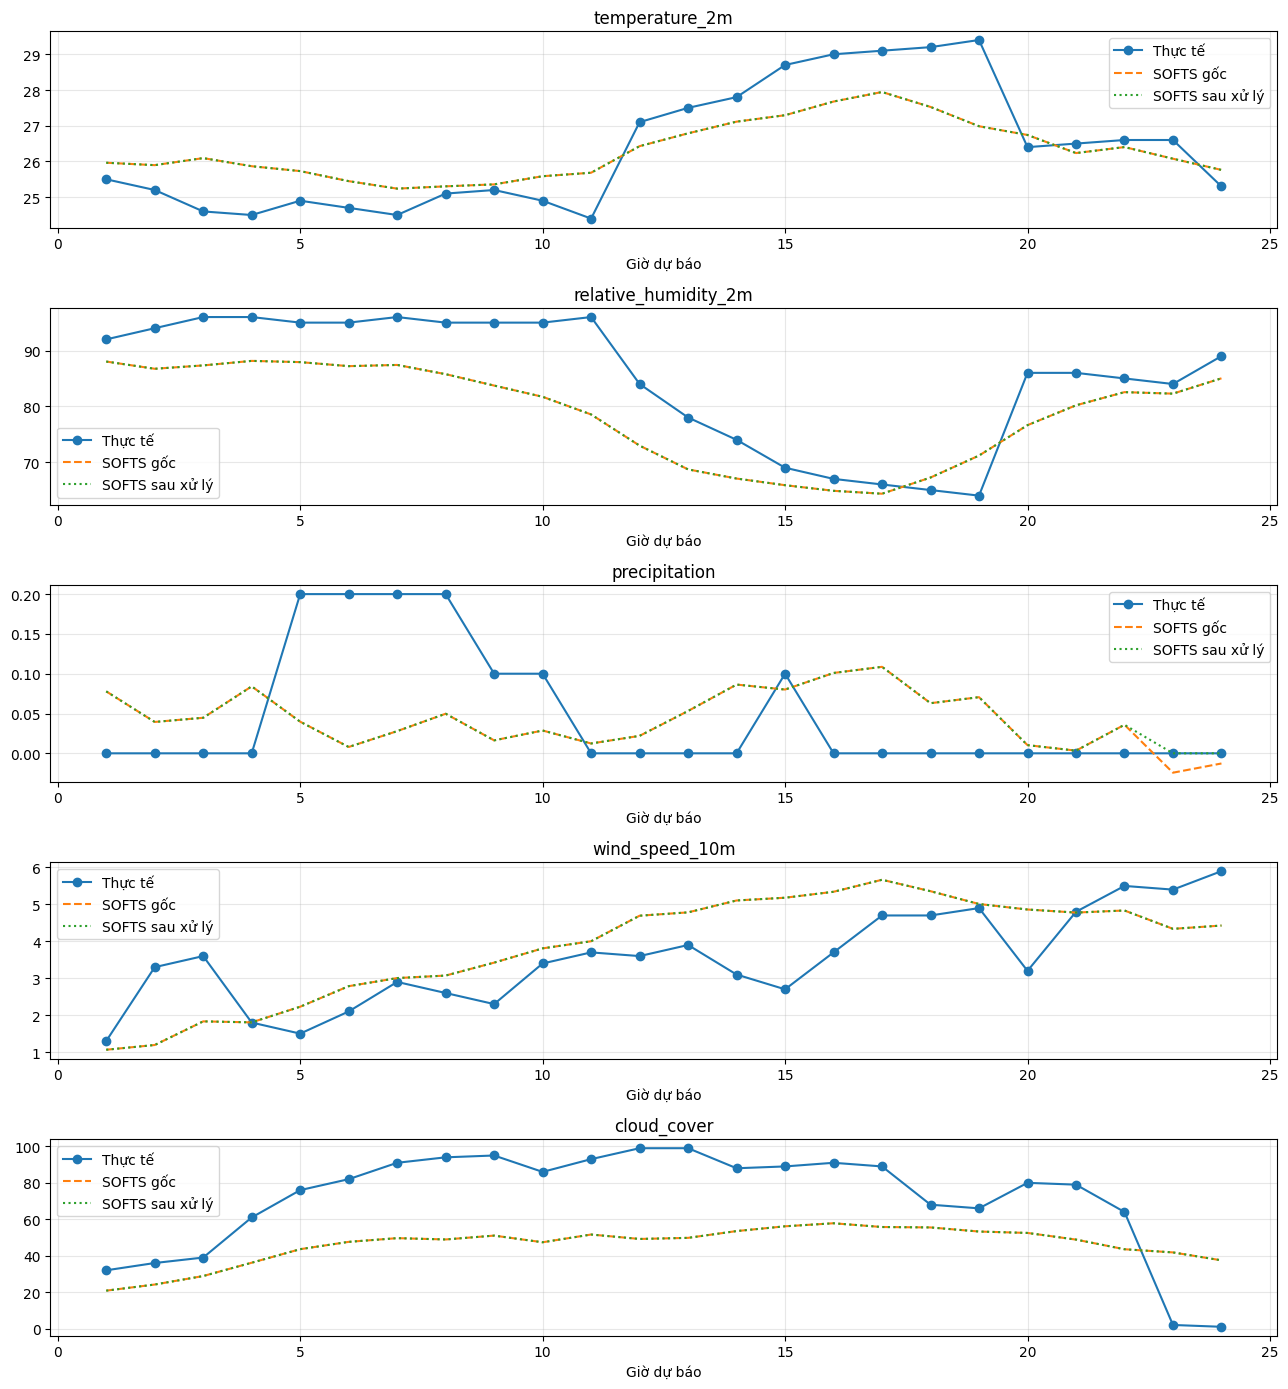


Đã lưu kết quả tại: /content/drive/MyDrive/SOFTS-HNweather/evaluation


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. SAO CHÉP DỰ BÁO GỐC
# ==========================================
raw_pred = pred_original.copy()
actual = true_original.copy()

# Tạo bản dự báo đã xử lý
processed_pred = raw_pred.copy()

feature_idx = {
    name: i for i, name in enumerate(features)
}

# Lượng mưa không thể âm
i = feature_idx["precipitation"]
processed_pred[:, :, i] = np.maximum(
    processed_pred[:, :, i], 0
)

# Tốc độ gió không thể âm
i = feature_idx["wind_speed_10m"]
processed_pred[:, :, i] = np.maximum(
    processed_pred[:, :, i], 0
)

# Độ ẩm trong khoảng 0–100%
i = feature_idx["relative_humidity_2m"]
processed_pred[:, :, i] = np.clip(
    processed_pred[:, :, i], 0, 100
)

# Độ che phủ mây trong khoảng 0–100%
i = feature_idx["cloud_cover"]
processed_pred[:, :, i] = np.clip(
    processed_pred[:, :, i], 0, 100
)

# Không tự đặt giới hạn cho nhiệt độ
# vì cần căn cứ nguồn dữ liệu và điều kiện đánh giá.

# ==========================================
# 2. SO SÁNH MAE, RMSE TRƯỚC VÀ SAU
# ==========================================
rows = []

for i, feature in enumerate(features):
    y_true = actual[:, :, i].ravel()
    y_raw = raw_pred[:, :, i].ravel()
    y_processed = processed_pred[:, :, i].ravel()

    mae_raw = np.mean(np.abs(y_true - y_raw))
    rmse_raw = np.sqrt(np.mean((y_true - y_raw) ** 2))

    mae_processed = np.mean(
        np.abs(y_true - y_processed)
    )
    rmse_processed = np.sqrt(
        np.mean((y_true - y_processed) ** 2)
    )

    rows.append({
        "Biến": feature,
        "MAE gốc": mae_raw,
        "MAE sau xử lý": mae_processed,
        "Chênh lệch MAE": mae_processed - mae_raw,
        "RMSE gốc": rmse_raw,
        "RMSE sau xử lý": rmse_processed,
        "Số giá trị thay đổi": int(
            np.count_nonzero(
                np.abs(y_processed - y_raw) > 1e-8
            )
        )
    })

comparison = pd.DataFrame(rows)

print("===== SO SÁNH TRƯỚC VÀ SAU HẬU XỬ LÝ =====")
display(comparison.round(4))

# Chênh lệch MAE âm: sai số giảm
# Chênh lệch MAE dương: sai số tăng

# ==========================================
# 3. KIỂM TRA LẠI CÁC GIỚI HẠN
# ==========================================
checks = []

for i, feature in enumerate(features):
    values = processed_pred[:, :, i].ravel()

    if feature in [
        "relative_humidity_2m",
        "cloud_cover"
    ]:
        invalid = (values < 0) | (values > 100)

    elif feature in [
        "precipitation",
        "wind_speed_10m"
    ]:
        invalid = values < 0

    else:
        invalid = np.zeros(
            len(values), dtype=bool
        )

    checks.append({
        "Biến": feature,
        "Min sau xử lý": values.min(),
        "Max sau xử lý": values.max(),
        "Số giá trị vi phạm": int(invalid.sum())
    })

print("\n===== KIỂM TRA LẠI ĐẦU RA =====")
display(pd.DataFrame(checks).round(4))

# ==========================================
# 4. VẼ SO SÁNH CHO MỘT CỬA SỔ 24 GIỜ
# ==========================================
fig, axes = plt.subplots(
    len(features), 1,
    figsize=(13, 14)
)

for i, feature in enumerate(features):
    axes[i].plot(
        range(1, PRED_LEN + 1),
        actual[0, :, i],
        marker="o",
        label="Thực tế"
    )

    axes[i].plot(
        range(1, PRED_LEN + 1),
        raw_pred[0, :, i],
        linestyle="--",
        label="SOFTS gốc"
    )

    axes[i].plot(
        range(1, PRED_LEN + 1),
        processed_pred[0, :, i],
        linestyle=":",
        label="SOFTS sau xử lý"
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Giờ dự báo")
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

# ==========================================
# 5. LƯU KẾT QUẢ
# ==========================================
out_dir = Path(
    "/content/drive/MyDrive/SOFTS-HNweather/evaluation"
)
out_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    out_dir / "raw_vs_postprocessed_metrics.csv",
    index=False
)

# Lưu dự báo đã xử lý cùng giá trị thực tế
n_windows = processed_pred.shape[0]
n_rows = n_windows * PRED_LEN

forecast_dates = pd.to_datetime(
    test_data["date"].iloc[
        SEQ_LEN:SEQ_LEN + n_rows
    ]
).reset_index(drop=True)

result_df = pd.DataFrame({
    "date": forecast_dates
})

for i, feature in enumerate(features):
    result_df[f"actual_{feature}"] = (
        actual[:, :, i].reshape(-1)
    )
    result_df[f"predicted_{feature}"] = (
        processed_pred[:, :, i].reshape(-1)
    )

result_df.to_csv(
    out_dir / "test_predictions_24h_constrained.csv",
    index=False
)

print("\nĐã lưu kết quả tại:", out_dir)

In [18]:
import os
import json
import shutil
import time
from pathlib import Path
from types import SimpleNamespace

import pandas as pd
import torch
import joblib
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. ĐƯỜNG DẪN VÀ KIỂM TRA
# ==========================================
repo = Path("/content/SOFTS-HNweather")
drive_dir = Path("/content/drive/MyDrive/SOFTS-HNweather")
csv_path = drive_dir / "hanoi_weather.csv"

os.chdir(repo)

assert csv_path.exists(), f"Không tìm thấy dữ liệu: {csv_path}"
assert torch.cuda.is_available(), "Colab chưa bật GPU!"
assert "Exp_Custom" in globals(), (
    "Không tìm thấy Exp_Custom. "
    "Hãy chạy các cell sửa lỗi SOFTS trước đó."
)

# ==========================================
# 2. ĐỌC TOÀN BỘ DỮ LIỆU
# ==========================================
all_df = pd.read_csv(csv_path)
all_df["date"] = pd.to_datetime(all_df["date"])
all_df = all_df.sort_values("date").reset_index(drop=True)

assert not all_df["date"].duplicated().any()
assert not all_df.isna().any().any()

features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover",
]

assert all(col in all_df.columns for col in features)

print("Số dòng dữ liệu:", len(all_df))
print("Thời điểm bắt đầu:", all_df["date"].min())
print("Thời điểm kết thúc:", all_df["date"].max())

# ==========================================
# 3. TẠO SCALER RIÊNG CHO MÔ HÌNH TRIỂN KHAI
# ==========================================
final_scaler = StandardScaler()
final_scaler.fit(all_df[features])

all_scaled = all_df.copy()
all_scaled[features] = final_scaler.transform(
    all_df[features]
)

# ==========================================
# 4. KHỞI TẠO SOFTS MỚI
# ==========================================
args_final = SimpleNamespace(**vars(args))

args_final.seq_len = 168
args_final.pred_len = 24
args_final.train_stride = 6
args_final.eval_stride = 24
args_final.checkpoints = "./checkpoints/"
args_final.train_epochs = 10
args_final.patience = 3
args_final.save_model = True

FINAL_SETTING = "HanoiWeather_SOFTS_FINAL_168_24"

final_exp = Exp_Custom(args_final)

print("GPU:", torch.cuda.get_device_name(0))
print("Setting:", FINAL_SETTING)

# ==========================================
# 5. HUẤN LUYỆN LẠI VỚI TOÀN BỘ LỊCH SỬ
# ==========================================
print("\nBắt đầu huấn luyện mô hình triển khai...")

start = time.time()

final_exp.train(
    FINAL_SETTING,
    train_data=all_scaled,
    vali_data=all_scaled,
    test_data=None,
)

print(
    f"\nThời gian chạy: "
    f"{(time.time() - start) / 60:.2f} phút"
)

# Lưu ý:
# Ở bước này, train và vali dùng cùng dữ liệu để tận dụng
# toàn bộ lịch sử. Vì vậy, validation loss lần này KHÔNG
# phải kết quả đánh giá độc lập và không thay thế test metrics cũ.

# ==========================================
# 6. LƯU BỘ MÔ HÌNH VÀO GOOGLE DRIVE
# ==========================================
local_dir = repo / "checkpoints" / FINAL_SETTING
deploy_dir = drive_dir / "checkpoints" / FINAL_SETTING
deploy_dir.mkdir(parents=True, exist_ok=True)

checkpoint = local_dir / "checkpoint.pth"

assert checkpoint.exists(), (
    f"Không tìm thấy checkpoint: {checkpoint}"
)

shutil.copy2(
    checkpoint,
    deploy_dir / "checkpoint.pth"
)

joblib.dump(
    final_scaler,
    deploy_dir / "scaler.pkl"
)

config = {
    "model": "SOFTS",
    "seq_len": 168,
    "pred_len": 24,
    "features": features,
    "freq": "h",
    "d_model": args_final.d_model,
    "d_core": args_final.d_core,
    "d_ff": args_final.d_ff,
    "e_layers": args_final.e_layers,
    "dropout": args_final.dropout,
    "activation": args_final.activation,
    "use_norm": args_final.use_norm,
    "train_stride": args_final.train_stride,
    "scaler_type": "StandardScaler",
    "data_start": str(all_df["date"].min()),
    "data_end": str(all_df["date"].max()),
    "output_constraints": {
        "relative_humidity_2m": [0, 100],
        "precipitation": [0, None],
        "wind_speed_10m": [0, None],
        "cloud_cover": [0, 100],
    },
}

with open(
    deploy_dir / "config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("\nĐÃ LƯU MÔ HÌNH TRIỂN KHAI:")
print(deploy_dir)
print(" - checkpoint.pth")
print(" - scaler.pkl")
print(" - config.json")

Số dòng dữ liệu: 753883
Thời điểm bắt đầu: 1940-01-01 05:00:00
Thời điểm kết thúc: 2025-12-31 23:00:00
Use GPU: cuda:0
GPU: Tesla T4
Setting: HanoiWeather_SOFTS_FINAL_168_24

Bắt đầu huấn luyện mô hình triển khai...
	iters: 100, epoch: 1 | loss: 0.5916607
	speed: 0.0099s/iter; left time: 192.7527s
	iters: 200, epoch: 1 | loss: 0.6246112
	speed: 0.0071s/iter; left time: 138.8988s
	iters: 300, epoch: 1 | loss: 0.7501510
	speed: 0.0077s/iter; left time: 149.3064s
	iters: 400, epoch: 1 | loss: 0.5579787
	speed: 0.0073s/iter; left time: 141.2166s
	iters: 500, epoch: 1 | loss: 0.4024222
	speed: 0.0072s/iter; left time: 137.5855s
	iters: 600, epoch: 1 | loss: 0.4894521
	speed: 0.0073s/iter; left time: 139.3308s
	iters: 700, epoch: 1 | loss: 1.1019922
	speed: 0.0071s/iter; left time: 133.8912s
	iters: 800, epoch: 1 | loss: 0.3662232
	speed: 0.0073s/iter; left time: 137.7650s
	iters: 900, epoch: 1 | loss: 0.4659483
	speed: 0.0073s/iter; left time: 136.5657s
	iters: 1000, epoch: 1 | loss: 0.3499

In [20]:
import torch
import transformers
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("GPU khả dụng:", torch.cuda.is_available())

from transformers import AutoImageProcessor, AutoModel

print("Import DINOv3 components: OK")

PyTorch: 2.11.0+cu130
Transformers: 4.57.6
Hugging Face Hub: 0.36.2
GPU khả dụng: True
Import DINOv3 components: OK


In [23]:
from huggingface_hub import notebook_login, whoami

notebook_login()

# Kiểm tra tài khoản đã đăng nhập
print("Tài khoản Hugging Face:", whoami()["name"])

Tài khoản Hugging Face: QBarooooo


In [24]:
import torch
from transformers import AutoImageProcessor, AutoModel

MODEL_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
dinov3_model = AutoModel.from_pretrained(MODEL_ID)

device = "cuda" if torch.cuda.is_available() else "cpu"
dinov3_model = dinov3_model.to(device)
dinov3_model.eval()

print("Tải DINOv3 thành công!")
print("Thiết bị:", device)
print("Số chiều đặc trưng:", dinov3_model.config.hidden_size)

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/86.4M [00:00<?, ?B/s]

Tải DINOv3 thành công!
Thiết bị: cuda
Số chiều đặc trưng: 384


In [25]:
from pathlib import Path

repo = Path("/content/SOFTS-HNweather")
model_dir = repo / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_code = r'''
import numpy as np
import torch
import torch.nn as nn

from PIL import Image, ImageDraw
from transformers import AutoImageProcessor, AutoModel


MODEL_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"


def weather_window_to_image(window, size=224):
    """
    Chuyển một cửa sổ thời tiết [seq_len, n_features]
    thành ảnh RGB gồm các biểu đồ thời gian xếp dọc.

    window phải được chuẩn hóa bằng scaler đã fit trên train.
    """
    window = np.asarray(window, dtype=np.float32)

    if window.ndim != 2:
        raise ValueError("window phải có dạng [seq_len, n_features].")

    window = np.nan_to_num(
        window, nan=0.0, posinf=3.0, neginf=-3.0
    )

    seq_len, n_features = window.shape
    image = Image.new(
        "RGB", (size, size), color=(250, 250, 250)
    )
    draw = ImageDraw.Draw(image)

    # Mỗi biến có một ô biểu đồ riêng.
    # Màu sắc chỉ dùng để phân biệt các đường.
    colors = [
        (220, 65, 65),    # temperature
        (35, 145, 80),    # humidity
        (40, 105, 220),   # precipitation
        (150, 75, 180),   # wind
        (80, 90, 105),    # cloud cover
    ]

    left, right = 5, size - 6
    top_margin, bottom_margin = 4, 4
    panel_height = size / n_features

    x_coords = np.linspace(
        left, right, seq_len
    ).astype(int)

    for j in range(n_features):
        top = int(j * panel_height)
        bottom = int((j + 1) * panel_height) - 1

        # Đường phân cách giữa các biến
        if j > 0:
            draw.line(
                (0, top, size - 1, top),
                fill=(215, 219, 225),
                width=1
            )

        y_top = top + top_margin
        y_bottom = bottom - bottom_margin

        # Dữ liệu đã chuẩn hóa: giữ cùng một thang đo
        # giữa các cửa sổ, tránh tự co giãn từng cửa sổ.
        values = np.clip(window[:, j], -3.0, 3.0)
        normalized = (values + 3.0) / 6.0

        y_coords = (
            y_bottom
            - normalized * (y_bottom - y_top)
        ).astype(int)

        points = list(zip(
            x_coords.tolist(),
            y_coords.tolist()
        ))

        if len(points) >= 2:
            draw.line(
                points,
                fill=colors[j % len(colors)],
                width=2
            )

    return image


class Model(nn.Module):
    """
    Mô hình thử nghiệm thay encoder STAR của SOFTS bằng DINOv3.
    Đầu vào: [batch, seq_len, n_features].
    Đầu ra: [batch, pred_len, n_features].
    """

    def __init__(self, configs):
        super().__init__()

        self.seq_len = int(configs.seq_len)
        self.pred_len = int(configs.pred_len)
        self.n_features = int(
            getattr(configs, "enc_in", 5)
        )

        model_id = getattr(
            configs, "dinov3_model_id", MODEL_ID
        )

        # ENCODER THAY THẾ: DINOv3.
        # Không tạo STAR hoặc DataEmbedding_inverted.
        self.processor = AutoImageProcessor.from_pretrained(
            model_id
        )
        self.encoder = AutoModel.from_pretrained(model_id)

        for parameter in self.encoder.parameters():
            parameter.requires_grad = False

        hidden_size = self.encoder.config.hidden_size

        # Forecasting head mới ánh xạ đặc trưng DINOv3
        # thành pred_len x n_features.
        self.forecast_head = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Linear(hidden_size, 256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(
                256, self.pred_len * self.n_features
            )
        )

        self.encoder.eval()

    def train(self, mode=True):
        # Cho phép head train, nhưng luôn giữ DINOv3 ở eval.
        super().train(mode)
        self.encoder.eval()
        return self

    def encode(self, x_enc):
        """
        Trích xuất CLS embedding của DINOv3 từ cửa sổ thời tiết.
        Trả về [batch, 384] với ViT-S/16.
        """
        if x_enc.ndim != 3:
            raise ValueError(
                "x_enc phải có dạng [batch, seq_len, n_features]."
            )

        if x_enc.shape[1] != self.seq_len:
            raise ValueError(
                f"Cần {self.seq_len} giờ đầu vào, "
                f"nhận được {x_enc.shape[1]}."
            )

        if x_enc.shape[2] != self.n_features:
            raise ValueError(
                f"Cần {self.n_features} biến, "
                f"nhận được {x_enc.shape[2]}."
            )

        # Vẽ ảnh từ dữ liệu số; DINOv3 được đóng băng,
        # vì vậy không cần gradient qua bước chuyển đổi này.
        windows = x_enc.detach().float().cpu().numpy()

        images = [
            weather_window_to_image(window)
            for window in windows
        ]

        pixel_values = self.processor(
            images=images,
            return_tensors="pt"
        )["pixel_values"]

        device = next(self.encoder.parameters()).device
        pixel_values = pixel_values.to(device)

        with torch.no_grad():
            outputs = self.encoder(
                pixel_values=pixel_values
            )
            embeddings = outputs.last_hidden_state[:, 0, :]

        return embeddings

    def forward(
        self,
        x_enc,
        x_mark_enc=None,
        x_dec=None,
        x_mark_dec=None,
        mask=None
    ):
        # x_enc phải được chuẩn hóa bằng scaler đã fit trên train.
        embeddings = self.encode(x_enc)

        output = self.forecast_head(embeddings)

        return output.reshape(
            x_enc.shape[0],
            self.pred_len,
            self.n_features
        )
'''

model_file = model_dir / "SOFTS_DINOv3.py"
model_file.write_text(model_code, encoding="utf-8")

print("Đã tạo:", model_file)
print("File SOFTS gốc không bị thay đổi.")

Đã tạo: /content/SOFTS-HNweather/models/SOFTS_DINOv3.py
File SOFTS gốc không bị thay đổi.


In [26]:
import os
import sys
import torch
from types import SimpleNamespace

repo = "/content/SOFTS-HNweather"
os.chdir(repo)

if repo not in sys.path:
    sys.path.insert(0, repo)

from models.SOFTS_DINOv3 import Model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

config_dino = SimpleNamespace(
    seq_len=168,
    pred_len=24,
    enc_in=5,
    dinov3_model_id=(
        "facebook/dinov3-vits16-pretrain-lvd1689m"
    ),
)

dinov3_ts_model = Model(config_dino).to(device)

# Thử một batch giả để xác minh đường xử lý
x_dummy = torch.randn(
    2, 168, 5,
    device=device
)

dinov3_ts_model.eval()

with torch.no_grad():
    embedding = dinov3_ts_model.encode(x_dummy)
    prediction = dinov3_ts_model(
        x_dummy, None, None, None
    )

print("Thiết bị:", device)
print("Đặc trưng encoder:", tuple(embedding.shape))
print("Kích thước đầu ra:", tuple(prediction.shape))
print(
    "STAR có trong mô hình mới:",
    any(
        module.__class__.__name__ == "STAR"
        for module in dinov3_ts_model.modules()
    )
)

Thiết bị: cuda
Đặc trưng encoder: (2, 384)
Kích thước đầu ra: (2, 24, 5)
STAR có trong mô hình mới: False


In [27]:
import os
import numpy as np
import torch

from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# ============================================
# 1. KIỂM TRA MÔI TRƯỜNG
# ============================================
repo = Path("/content/SOFTS-HNweather")
drive_dir = Path("/content/drive/MyDrive/SOFTS-HNweather")

os.chdir(repo)

assert "dinov3_ts_model" in globals(), (
    "Chưa có mô hình DINOv3. Hãy chạy lại cell kiểm tra mô hình."
)

assert "train_data" in globals()
assert "vali_data" in globals()
assert "test_data" in globals()

SEQ_LEN = 168
PRED_LEN = 24
TRAIN_STRIDE = 6
EVAL_STRIDE = 24

FEATURES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover",
]

device = next(
    dinov3_ts_model.encoder.parameters()
).device

for frame_name, frame in [
    ("train_data", train_data),
    ("vali_data", vali_data),
    ("test_data", test_data),
]:
    missing = [
        col for col in FEATURES
        if col not in frame.columns
    ]
    assert not missing, (
        f"{frame_name} thiếu cột: {missing}"
    )

print("Thiết bị:", device)
print("Train rows:", len(train_data))
print("Validation rows:", len(vali_data))
print("Test rows:", len(test_data))


# ============================================
# 2. TẠO CÁC CỬA SỔ THỜI GIAN
# ============================================
class WeatherWindowDataset(Dataset):
    def __init__(
        self,
        frame,
        features,
        seq_len=168,
        pred_len=24,
        stride=1
    ):
        self.values = frame[features].to_numpy(
            dtype=np.float32,
            copy=True
        )

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.stride = stride

        self.n_windows = max(
            0,
            (
                len(self.values)
                - seq_len
                - pred_len
                + 1
            ) // stride
        )

    def __len__(self):
        return self.n_windows

    def __getitem__(self, index):
        start = index * self.stride
        middle = start + self.seq_len
        end = middle + self.pred_len

        x = self.values[start:middle]
        y = self.values[middle:end]

        return (
            torch.from_numpy(x),
            torch.from_numpy(y)
        )


train_ds = WeatherWindowDataset(
    train_data, FEATURES,
    SEQ_LEN, PRED_LEN, TRAIN_STRIDE
)

val_ds = WeatherWindowDataset(
    vali_data, FEATURES,
    SEQ_LEN, PRED_LEN, EVAL_STRIDE
)

test_ds = WeatherWindowDataset(
    test_data, FEATURES,
    SEQ_LEN, PRED_LEN, EVAL_STRIDE
)

print("\nSố cửa sổ:")
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))


# ============================================
# 3. TÍNH VÀ LƯU ĐẶC TRƯNG DINOv3
# ============================================
cache_dir = (
    drive_dir
    / "evaluation"
    / "dinov3_feature_cache_v1"
)
cache_dir.mkdir(parents=True, exist_ok=True)

dinov3_ts_model.eval()


def extract_or_load_features(
    split_name,
    dataset,
    batch_size=32
):
    cache_path = cache_dir / f"{split_name}.npz"
    expected_count = len(dataset)

    # Dùng cache nếu kích thước phù hợp
    if cache_path.exists():
        with np.load(cache_path) as saved:
            embeddings = saved["embeddings"]
            targets = saved["targets"]

        if (
            embeddings.shape == (expected_count, 384)
            and targets.shape == (
                expected_count, PRED_LEN, len(FEATURES)
            )
        ):
            print(
                f"{split_name}: dùng cache có sẵn "
                f"{embeddings.shape}"
            )
            return embeddings, targets

        print(
            f"{split_name}: cache không khớp, "
            "sẽ trích xuất lại."
        )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    embedding_list = []
    target_list = []

    with torch.inference_mode():
        for batch_idx, (batch_x, batch_y) in enumerate(loader):
            batch_x = batch_x.to(device)

            # Dùng DINOv3 làm encoder.
            # Encoder bị đóng băng, không tính gradient.
            embeddings = dinov3_ts_model.encode(batch_x)

            embedding_list.append(
                embeddings.float().cpu().numpy()
            )

            target_list.append(batch_y.numpy())

            if (batch_idx + 1) % 100 == 0:
                print(
                    f"{split_name}: "
                    f"{batch_idx + 1}/{len(loader)} batches"
                )

    embeddings = np.concatenate(
        embedding_list, axis=0
    ).astype(np.float32)

    targets = np.concatenate(
        target_list, axis=0
    ).astype(np.float32)

    np.savez(
        cache_path,
        embeddings=embeddings,
        targets=targets
    )

    print(
        f"{split_name}: đã lưu {embeddings.shape} "
        f"vào {cache_path}"
    )

    return embeddings, targets


train_embeddings, train_targets = (
    extract_or_load_features("train", train_ds)
)

val_embeddings, val_targets = (
    extract_or_load_features("validation", val_ds)
)

test_embeddings, test_targets = (
    extract_or_load_features("test", test_ds)
)


# ============================================
# 4. XÁC NHẬN KẾT QUẢ
# ============================================
print("\n===== HOÀN THÀNH =====")

print("Train embeddings:", train_embeddings.shape)
print("Train targets:", train_targets.shape)

print("Validation embeddings:", val_embeddings.shape)
print("Validation targets:", val_targets.shape)

print("Test embeddings:", test_embeddings.shape)
print("Test targets:", test_targets.shape)

print("Thư mục cache:", cache_dir)

Thiết bị: cuda:0
Train rows: 527718
Validation rows: 75556
Test rows: 150945

Số cửa sổ:
Train: 87921
Validation: 3140
Test: 6281
train: 100/2748 batches
train: 200/2748 batches
train: 300/2748 batches
train: 400/2748 batches
train: 500/2748 batches
train: 600/2748 batches
train: 700/2748 batches
train: 800/2748 batches
train: 900/2748 batches
train: 1000/2748 batches
train: 1100/2748 batches
train: 1200/2748 batches
train: 1300/2748 batches
train: 1400/2748 batches
train: 1500/2748 batches
train: 1600/2748 batches
train: 1700/2748 batches
train: 1800/2748 batches
train: 1900/2748 batches
train: 2000/2748 batches
train: 2100/2748 batches
train: 2200/2748 batches
train: 2300/2748 batches
train: 2400/2748 batches
train: 2500/2748 batches
train: 2600/2748 batches
train: 2700/2748 batches
train: đã lưu (87921, 384) vào /content/drive/MyDrive/SOFTS-HNweather/evaluation/dinov3_feature_cache_v1/train.npz
validation: đã lưu (3140, 384) vào /content/drive/MyDrive/SOFTS-HNweather/evaluation/dino

In [28]:
import os
import json
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

# ==================================================
# 1. CẤU HÌNH
# ==================================================
repo = Path("/content/SOFTS-HNweather")
drive_dir = Path("/content/drive/MyDrive/SOFTS-HNweather")
eval_dir = drive_dir / "evaluation"

os.chdir(repo)

FEATURES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover",
]

SEQ_LEN = 168
PRED_LEN = 24
BATCH_SIZE = 512
MAX_EPOCHS = 30
PATIENCE = 5

device = next(dinov3_ts_model.encoder.parameters()).device
head = dinov3_ts_model.forecast_head

# Đóng băng DINOv3, chỉ huấn luyện forecasting head
for p in dinov3_ts_model.encoder.parameters():
    p.requires_grad = False

for p in head.parameters():
    p.requires_grad = True

# Cố định seed và khởi tạo lại head để thí nghiệm
# có thể tái lập từ cùng một seed.
random.seed(2026)
np.random.seed(2026)
torch.manual_seed(2026)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(2026)

for module in head.modules():
    if isinstance(module, (nn.Linear, nn.LayerNorm)):
        module.reset_parameters()

# ==================================================
# 2. KIỂM TRA DỮ LIỆU ĐẶC TRƯNG ĐÃ CÓ
# ==================================================
required_arrays = [
    "train_embeddings", "train_targets",
    "val_embeddings", "val_targets",
    "test_embeddings", "test_targets",
]

for name in required_arrays:
    assert name in globals(), (
        f"Thiếu biến {name}. Hãy chạy lại cell trích xuất đặc trưng."
    )

print("Thiết bị:", device)
print("Train:", train_embeddings.shape, train_targets.shape)
print("Validation:", val_embeddings.shape, val_targets.shape)
print("Test:", test_embeddings.shape, test_targets.shape)

# ==================================================
# 3. TẠO DATALOADER
# ==================================================
def make_loader(x, y, shuffle=False):
    x_tensor = torch.from_numpy(
        np.ascontiguousarray(x, dtype=np.float32)
    )
    y_tensor = torch.from_numpy(
        np.ascontiguousarray(y, dtype=np.float32)
    )

    return DataLoader(
        TensorDataset(x_tensor, y_tensor),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        generator=torch.Generator().manual_seed(2026)
        if shuffle else None,
    )

train_loader = make_loader(
    train_embeddings, train_targets, shuffle=True
)

val_loader = make_loader(
    val_embeddings, val_targets
)

# ==================================================
# 4. KHỞI TẠO OPTIMIZER
# ==================================================
criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    head.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

# Thư mục checkpoint riêng, không ghi đè SOFTS gốc
setting = "HanoiWeather_DINOv3_Encoder_168_24"
model_dir = drive_dir / "checkpoints" / setting
model_dir.mkdir(parents=True, exist_ok=True)

best_path = model_dir / "forecast_head.pth"

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0
history = []

# ==================================================
# 5. HUẤN LUYỆN FORECASTING HEAD
# ==================================================
for epoch in range(1, MAX_EPOCHS + 1):

    # ----- Train -----
    head.train()
    train_loss_sum = 0.0
    train_count = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = head(batch_x).reshape(
            -1, PRED_LEN, len(FEATURES)
        )

        loss = criterion(outputs, batch_y)
        loss.backward()

        # Giới hạn gradient để giảm nguy cơ cập nhật quá lớn
        torch.nn.utils.clip_grad_norm_(
            head.parameters(), max_norm=1.0
        )

        optimizer.step()

        train_loss_sum += loss.item() * len(batch_x)
        train_count += len(batch_x)

    train_loss = train_loss_sum / train_count

    # ----- Validation -----
    head.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)

            outputs = head(batch_x).reshape(
                -1, PRED_LEN, len(FEATURES)
            )

            loss = criterion(outputs, batch_y)

            val_loss_sum += loss.item() * len(batch_x)
            val_count += len(batch_x)

    val_loss = val_loss_sum / val_count

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    # Lưu checkpoint tốt nhất theo validation loss
    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_epoch = epoch
        patience_counter = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in head.state_dict().items()
        }

        torch.save(best_state, best_path)

        print("  -> Đã lưu checkpoint tốt nhất.")
    else:
        patience_counter += 1
        print(
            f"  -> Validation chưa cải thiện: "
            f"{patience_counter}/{PATIENCE}"
        )

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

# Nạp lại trọng số head tốt nhất
best_state = torch.load(best_path, map_location=device)
head.load_state_dict(best_state)
head.eval()

history_df = pd.DataFrame(history)
history_df.to_csv(
    model_dir / "training_history.csv",
    index=False
)

print("\n===== HUẤN LUYỆN HOÀN TẤT =====")
print("Epoch tốt nhất:", best_epoch)
print("Validation loss tốt nhất:", best_val_loss)
print("Checkpoint:", best_path)

# ==================================================
# 6. DỰ BÁO TRÊN TẬP TEST
# ==================================================
test_x_tensor = torch.from_numpy(
    np.ascontiguousarray(test_embeddings, dtype=np.float32)
)

test_feature_loader = DataLoader(
    TensorDataset(test_x_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

pred_scaled_batches = []

head.eval()

with torch.no_grad():
    for (batch_x,) in test_feature_loader:
        batch_x = batch_x.to(device, non_blocking=True)

        outputs = head(batch_x).reshape(
            -1, PRED_LEN, len(FEATURES)
        )

        pred_scaled_batches.append(
            outputs.cpu().numpy()
        )

dino_pred_scaled = np.concatenate(
    pred_scaled_batches, axis=0
)

# Dùng scaler của thí nghiệm SOFTS gốc để đảm bảo
# hai mô hình được so sánh trong cùng hệ đơn vị.
if "scaler" in globals():
    eval_scaler = scaler
else:
    import joblib

    scaler_path = (
        drive_dir
        / "checkpoints"
        / "HanoiWeather_SOFTS_168_24"
        / "scaler.pkl"
    )
    eval_scaler = joblib.load(scaler_path)

n_features = len(FEATURES)

dino_pred_original = eval_scaler.inverse_transform(
    dino_pred_scaled.reshape(-1, n_features)
).reshape(dino_pred_scaled.shape)

dino_true_original = eval_scaler.inverse_transform(
    test_targets.reshape(-1, n_features)
).reshape(test_targets.shape)

print("DINOv3 prediction:", dino_pred_original.shape)
print("Actual:", dino_true_original.shape)

# ==================================================
# 7. SO SÁNH VỚI KẾT QUẢ SOFTS GỐC ĐÃ LƯU
# ==================================================
softs_file = eval_dir / "test_predictions_24h.csv"

assert softs_file.exists(), (
    f"Không tìm thấy kết quả SOFTS gốc: {softs_file}"
)

softs_df = pd.read_csv(softs_file)

assert len(softs_df) == (
    len(dino_pred_original) * PRED_LEN
), "Số dòng SOFTS không khớp với cửa sổ test DINOv3."

comparison_rows = []

for i, feature in enumerate(FEATURES):
    y_true = dino_true_original[:, :, i].reshape(-1)
    y_dino = dino_pred_original[:, :, i].reshape(-1)

    y_softs = softs_df[
        f"predicted_{feature}"
    ].to_numpy(dtype=np.float64)

    mae_dino = np.mean(np.abs(y_true - y_dino))
    rmse_dino = np.sqrt(np.mean((y_true - y_dino) ** 2))

    mae_softs = np.mean(np.abs(y_true - y_softs))
    rmse_softs = np.sqrt(np.mean((y_true - y_softs) ** 2))

    improvement = (
        (mae_softs - mae_dino) / mae_softs * 100
        if mae_softs > 0 else np.nan
    )

    comparison_rows.append({
        "Biến": feature,
        "SOFTS MAE": mae_softs,
        "DINOv3 MAE": mae_dino,
        "SOFTS RMSE": rmse_softs,
        "DINOv3 RMSE": rmse_dino,
        "MAE cải thiện (%)": improvement,
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n===== SO SÁNH SOFTS VÀ DINOv3 ENCODER =====")
display(comparison_df.round(4))

# ==================================================
# 8. LƯU PREDICTIONS, METRICS VÀ CONFIG
# ==================================================
n_windows = len(dino_pred_original)
n_rows = n_windows * PRED_LEN

date_path = eval_dir / "test_predictions_24h.csv"
dates = pd.to_datetime(
    softs_df["date"]
).reset_index(drop=True)

dino_results = pd.DataFrame({
    "date": dates
})

for i, feature in enumerate(FEATURES):
    dino_results[f"actual_{feature}"] = (
        dino_true_original[:, :, i].reshape(-1)
    )
    dino_results[f"predicted_{feature}"] = (
        dino_pred_original[:, :, i].reshape(-1)
    )

dino_results.to_csv(
    eval_dir / "test_predictions_dinov3_24h.csv",
    index=False
)

comparison_df.to_csv(
    eval_dir / "softs_vs_dinov3_metrics.csv",
    index=False
)

config = {
    "model_name": "SOFTS_DINOv3_Encoder",
    "dinov3_model_id": (
        "facebook/dinov3-vits16-pretrain-lvd1689m"
    ),
    "seq_len": SEQ_LEN,
    "pred_len": PRED_LEN,
    "features": FEATURES,
    "encoder_hidden_size": 384,
    "encoder_frozen": True,
    "encoder_input": "weather_window_rendered_as_RGB_image",
    "forecast_head": "LayerNorm-Linear-GELU-Dropout-Linear",
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_val_loss),
    "training_seed": 2026,
}

with open(
    model_dir / "config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

print("\nĐÃ LƯU:")
print("Checkpoint:", best_path)
print("Lịch sử huấn luyện:", model_dir / "training_history.csv")
print("Bảng so sánh:", eval_dir / "softs_vs_dinov3_metrics.csv")
print("Dự báo DINOv3:", eval_dir / "test_predictions_dinov3_24h.csv")

Thiết bị: cuda:0
Train: (87921, 384) (87921, 24, 5)
Validation: (3140, 384) (3140, 24, 5)
Test: (6281, 384) (6281, 24, 5)
Epoch 01/30 | Train Loss: 0.842801 | Val Loss: 0.769630
  -> Đã lưu checkpoint tốt nhất.
Epoch 02/30 | Train Loss: 0.765473 | Val Loss: 0.739873
  -> Đã lưu checkpoint tốt nhất.
Epoch 03/30 | Train Loss: 0.739129 | Val Loss: 0.697821
  -> Đã lưu checkpoint tốt nhất.
Epoch 04/30 | Train Loss: 0.722007 | Val Loss: 0.717070
  -> Validation chưa cải thiện: 1/5
Epoch 05/30 | Train Loss: 0.709975 | Val Loss: 0.694106
  -> Đã lưu checkpoint tốt nhất.
Epoch 06/30 | Train Loss: 0.701405 | Val Loss: 0.687390
  -> Đã lưu checkpoint tốt nhất.
Epoch 07/30 | Train Loss: 0.691927 | Val Loss: 0.692718
  -> Validation chưa cải thiện: 1/5
Epoch 08/30 | Train Loss: 0.685318 | Val Loss: 0.650454
  -> Đã lưu checkpoint tốt nhất.
Epoch 09/30 | Train Loss: 0.680460 | Val Loss: 0.654534
  -> Validation chưa cải thiện: 1/5
Epoch 10/30 | Train Loss: 0.674134 | Val Loss: 0.666909
  -> Validat

,Biến,SOFTS MAE,DINOv3 MAE,SOFTS RMSE,DINOv3 RMSE,MAE cải thiện (%)
0,temperature_2m,1.3154,2.3762,1.8124,3.0593,-80.6412
1,relative_humidity_2m,5.5028,8.9375,7.4068,11.2637,-62.4192
2,precipitation,0.2441,0.2690,0.7633,0.7817,-10.1934
3,wind_speed_10m,2.3621,2.7105,3.1688,3.4838,-14.7520
4,cloud_cover,18.2652,23.6597,25.6142,28.9499,-29.5346



ĐÃ LƯU:
Checkpoint: /content/drive/MyDrive/SOFTS-HNweather/checkpoints/HanoiWeather_DINOv3_Encoder_168_24/forecast_head.pth
Lịch sử huấn luyện: /content/drive/MyDrive/SOFTS-HNweather/checkpoints/HanoiWeather_DINOv3_Encoder_168_24/training_history.csv
Bảng so sánh: /content/drive/MyDrive/SOFTS-HNweather/evaluation/softs_vs_dinov3_metrics.csv
Dự báo DINOv3: /content/drive/MyDrive/SOFTS-HNweather/evaluation/test_predictions_dinov3_24h.csv
